# multimodel_analysis v0.1.4 - Phase 1 results
This notebook exercises the bug fixes: input validation, full confusion matrices, numeric ROC AUC, recorded warnings/failed models, KNN regressor and the new defaults.

In [1]:
%matplotlib inline
import warnings
import numpy as np, pandas as pd
from sklearn.datasets import load_iris, load_breast_cancer, make_regression
import multimodel_analysis as mm
from multimodel_analysis import MultiModelClassifier, MultiModelRegressor
print(mm.__version__)

0.4.0


## 1. Multiclass classification (Iris, string labels)

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target.map(dict(enumerate(iris.target_names)))
clf = MultiModelClassifier(X, y, random_state=42)
models = clf.run_all_models()
df = clf.show_tabular_report(models, return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
                SVM  0.933333   0.934524 0.933333  0.933259 0.995556      0.001852
                KNN  0.933333   0.944444 0.933333  0.932660 0.994815      0.000764
  Gradient Boosting  0.933333   0.944444 0.933333  0.932660 0.998519      0.109664
           AdaBoost  0.933333   0.934524 0.933333  0.933259 0.980741      0.038596
      Decision Tree  0.911111   0.915535 0.911111  0.910714 0.933333      0.000987
Logistic Regression  0.911111   0.915535 0.911111  0.910714 0.995556      0.005247
        Naive Bayes  0.911111   0.915535 0.911111  0.910714 0.985185      0.000931
      Random Forest  0.888889   0.898148 0.888889  0.887767 0.992593      0.109418

* BEST MODEL RECOMMENDATION (by Accuracy): SVM
   Accuracy: 0.9333 | F1 Score: 0.9333



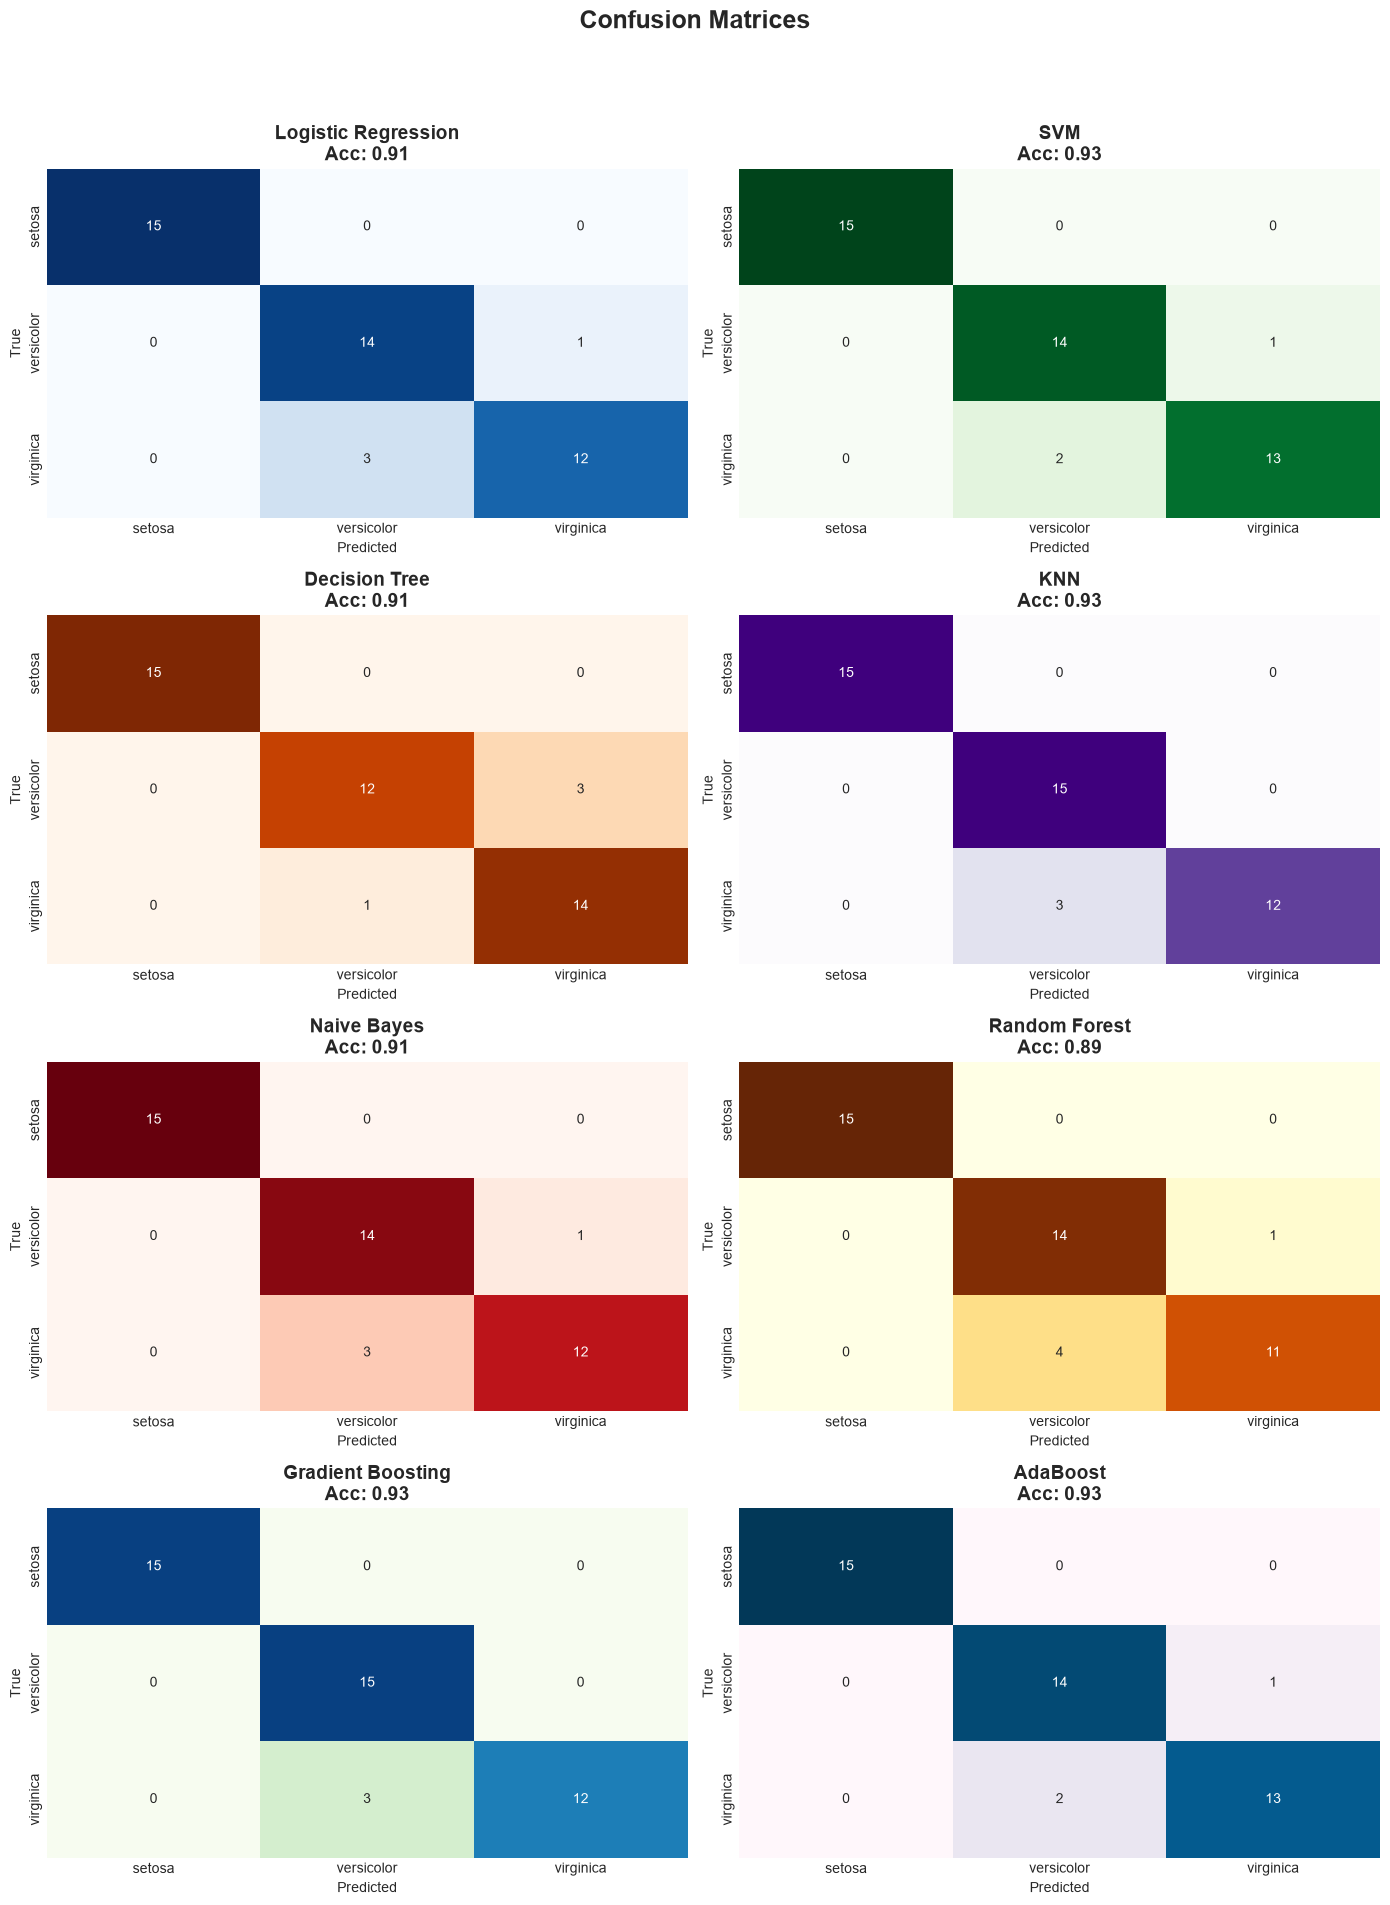

In [3]:
clf.plot_confusion_matrices(models)

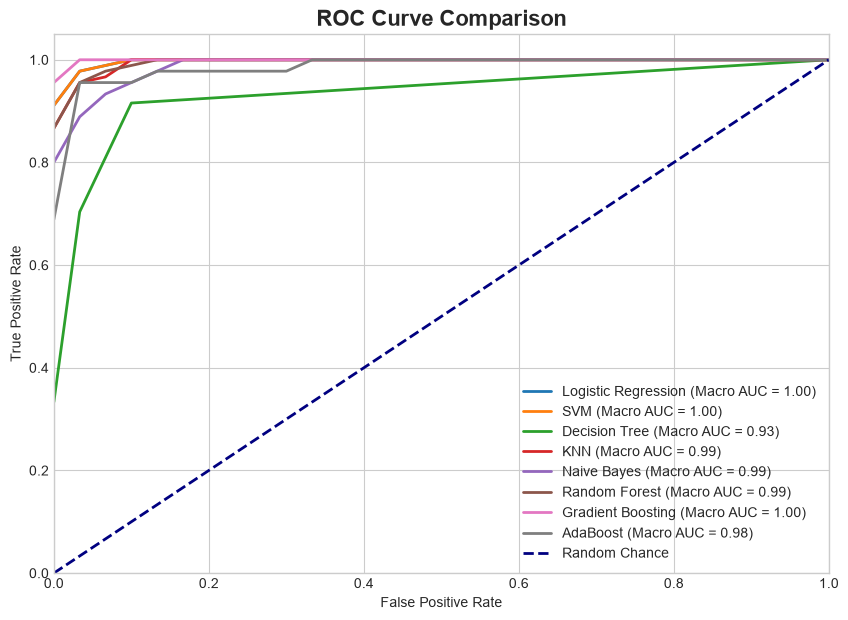

In [4]:
clf.plot_roc_curves(models)

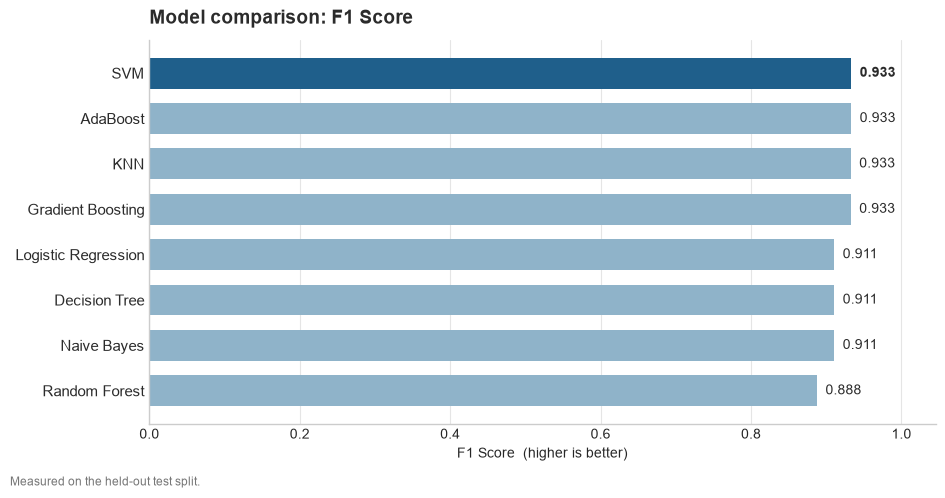

In [5]:
clf.plot_comparison(models)

## 2. Binary classification (Breast cancer) sorted by ROC AUC

In [6]:
bc = load_breast_cancer(as_frame=True)
clf2 = MultiModelClassifier(bc.data, bc.target, random_state=0)
clf2.run_all_models()
clf2.show_tabular_report(sort_by='ROC AUC', return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
Logistic Regression  0.959064   0.959259 0.959064  0.959127 0.995619      0.003549
                SVM  0.953216   0.953216 0.953216  0.953216 0.992699      0.008190
           AdaBoost  0.941520   0.941520 0.941520  0.941520 0.989048      0.070089
                KNN  0.935673   0.935639 0.935673  0.935345 0.987150      0.000810
  Gradient Boosting  0.935673   0.935936 0.935673  0.935771 0.986273      0.189634
      Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023      0.085498
        Naive Bayes  0.912281   0.912614 0.912281  0.912415 0.975321      0.000929
      Decision Tree  0.906433   0.908510 0.906433  0.906959 0.906396      0.003429

* BEST MODEL RECOMMENDATION (by ROC AUC): Logistic Regression
   Accuracy: 0.9591 | F1 Score: 0.9591



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Fit Time (s)
0,Logistic Regression,0.959064,0.959259,0.959064,0.959127,0.995619,0.003549
1,SVM,0.953216,0.953216,0.953216,0.953216,0.992699,0.008190
2,AdaBoost,0.941520,0.941520,0.941520,0.941520,0.989048,0.070089
3,KNN,0.935673,0.935639,0.935673,0.935345,0.987150,0.000810
4,Gradient Boosting,0.935673,0.935936,0.935673,0.935771,0.986273,0.189634
5,Random Forest,0.953216,0.953187,0.953216,0.953062,0.978023,0.085498
6,Naive Bayes,0.912281,0.912614,0.912281,0.912415,0.975321,0.000929
7,Decision Tree,0.906433,0.908510,0.906433,0.906959,0.906396,0.003429


## 3. Failures and warnings are recorded, not hidden

In [7]:
class Broken:
    def fit(self, X, y):
        raise RuntimeError('boom')

m = clf2.run_all_models(custom_models={'Broken model': Broken()})
print('failed:', clf2.failed_models_)
print('warnings:', clf2.warnings_)

[WARNING] Custom model 'Broken model' failed: boom
failed: {'Broken model': 'RuntimeError: boom'}
warnings: {'SVM': ['FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`']}


## 4. Clear errors for bad input

In [8]:
for label, args in {
    'continuous target': (X, np.random.rand(len(X))),
    'length mismatch': (X, y[:-5]),
    'NaN in X': (X.assign(**{X.columns[0]: np.where(np.arange(len(X)) == 0, np.nan, X.iloc[:, 0])}), y),
}.items():
    try:
        MultiModelClassifier(*args)
    except Exception as e:
        print(f'{label:18s} -> {type(e).__name__}: {e}'); print()

continuous target  -> ValueError: The target 'y' looks continuous (real-valued), which is a regression problem. Use MultiModelRegressor, or convert y to class labels before using MultiModelClassifier.

length mismatch    -> ValueError: X and y have different lengths: X has 150 rows but y has 145 values.

NaN in X           -> ValueError: X contains 1 missing (NaN) or infinite value(s). Impute or drop them first (e.g. X.fillna(X.median())).



## 5. Regression (now with KNN Regressor; SVR target-scaled)

In [9]:
Xr, yr = make_regression(n_samples=300, n_features=8, noise=10, random_state=1)
reg = MultiModelRegressor(Xr, yr, random_state=1)
rm = reg.run_all_models()
reg.show_tabular_report(rm, sort_by='RMSE', return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                      Model        MAE          MSE       RMSE  R2 Score  Fit Time (s)
          Linear Regression   7.824985    91.034435   9.541197  0.997713      0.000488
           Lasso Regression   7.878036    91.713250   9.576704  0.997696      0.000514
           Ridge Regression   7.997994    93.305211   9.659462  0.997656      0.000456
                        SVR  37.928997  3744.235476  61.190158  0.905932      0.001928
Gradient Boosting Regressor  50.714961  4581.490580  67.686709  0.884897      0.043113
              KNN Regressor  72.312597  9122.683519  95.512740  0.770807      0.000302
    Random Forest Regressor  79.507840  9926.535405  99.632000  0.750611      0.062063
         AdaBoost Regressor  84.337263 11790.890247 108.585866  0.703772      0.044945
    Decision Tree Regressor 120.032032 23680.705730 153.885366  0.405059      0.001268

* BEST MODEL RECOMMENDATION (by RMSE): Linear Regression
   R2 Score: 0.9977 | RMSE: 9.5412


,Model,MAE,MSE,RMSE,R2 Score,Fit Time (s)
0,Linear Regression,7.824985,91.034435,9.541197,0.997713,0.000488
1,Lasso Regression,7.878036,91.713250,9.576704,0.997696,0.000514
2,Ridge Regression,7.997994,93.305211,9.659462,0.997656,0.000456
3,SVR,37.928997,3744.235476,61.190158,0.905932,0.001928
4,Gradient Boosting Regressor,50.714961,4581.490580,67.686709,0.884897,0.043113
5,KNN Regressor,72.312597,9122.683519,95.512740,0.770807,0.000302
6,Random Forest Regressor,79.507840,9926.535405,99.632000,0.750611,0.062063
7,AdaBoost Regressor,84.337263,11790.890247,108.585866,0.703772,0.044945
8,Decision Tree Regressor,120.032032,23680.705730,153.885366,0.405059,0.001268


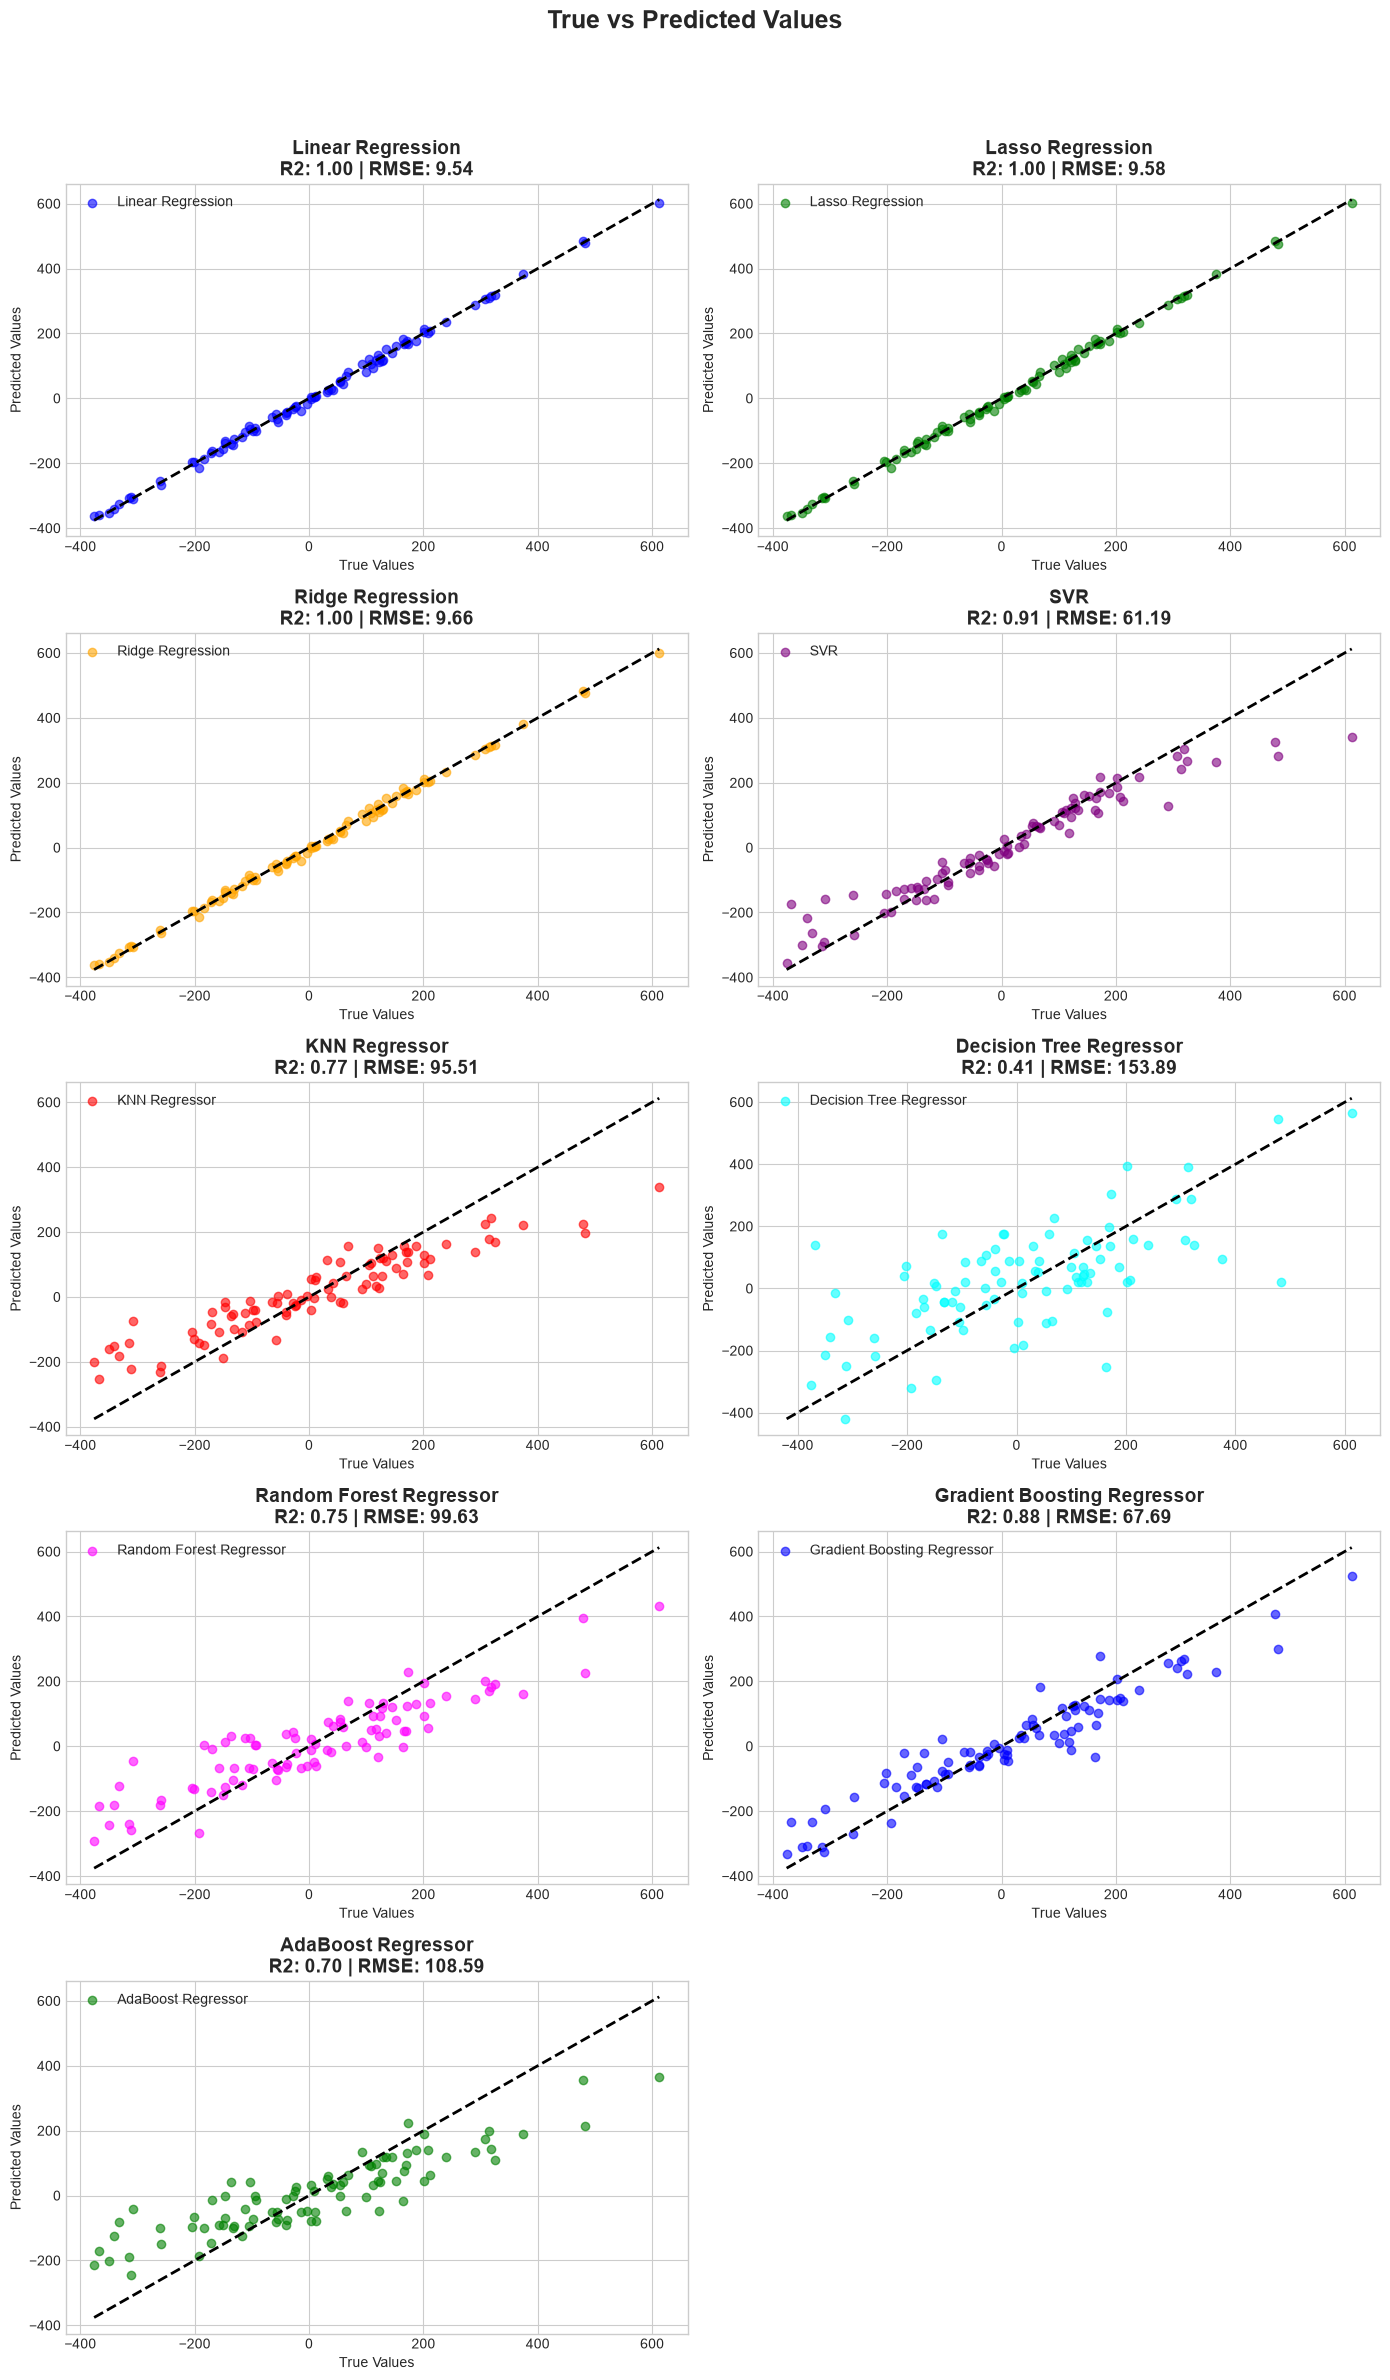

In [10]:
reg.plot_true_vs_predicted(rm)

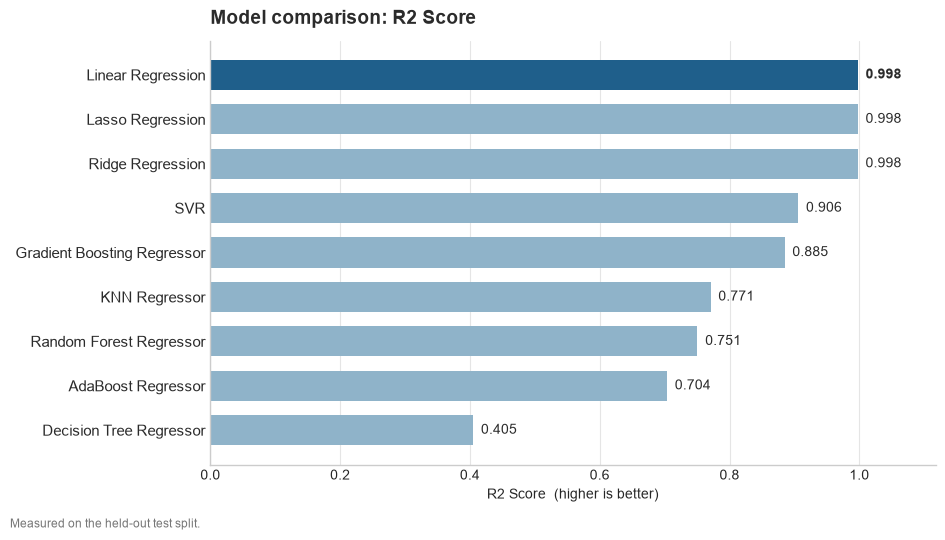

In [11]:
reg.plot_comparison(rm)